# Day 6 · Demo 2: Simpson's paradox

Bayesian statistics for PhD researchers, Aalborg University 2026. This notebook reproduces the figures of the **Day 6 afternoon slides**. Each section names its slide. Run it with the **R (bayes)** kernel from the `demos/` folder; the Stan model compiles the first time (about a minute).

The data are the slides' **illustrative** pilot study of the feedback game: 480 attempts, but the targets were not assigned evenly between the two conditions. A **hit** is an attempt within 0.5 s of the target.

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # dplyr for summaries, ggplot2 for figures
library(cmdstanr)    # Stan from R
set.seed(2026)
options(width = 95, repr.plot.width = 8, repr.plot.height = 5, repr.plot.bg = "white")
theme_set(theme_minimal(base_size = 14) + theme(legend.position = "top"))
condition_colours <- c("without feedback" = "navy", "with feedback" = "tomato")

pilot <- read_csv("data/slides-pilot-hits.csv", show_col_types = FALSE) |>   # attempt, feedback, target_seconds, hit
  mutate(x = target_seconds - 10,
         condition = factor(if_else(feedback == 1, "with feedback", "without feedback"),
                            levels = c("without feedback", "with feedback")))   # order for tables and legends
head(pilot)

This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /tmp/claude-0/-home-claude/12b37052-eed4-57b8-ae0f-6457ef895351/scratchpad/env/bin/cmdstan



- CmdStan version: 2.40.0



attempt,feedback,target_seconds,hit,x,condition
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,0,5,1,-5,without feedback
2,0,5,1,-5,without feedback
3,0,5,1,-5,without feedback
4,0,5,0,-5,without feedback
5,0,5,1,-5,without feedback
6,0,5,1,-5,without feedback


## 1. Does feedback help? Within every target versus overall

*Slides "Does feedback help? A pilot study" and "Within every target versus overall".*

group,condition,hits,attempts,share
<fct>,<fct>,<dbl>,<int>,<dbl>
5 s,without feedback,125,160,0.7812500
5 s,with feedback,17,20,0.8500000
10 s,without feedback,37,60,0.6166667
10 s,with feedback,42,60,0.7000000
15 s,without feedback,4,20,0.2000000
15 s,with feedback,63,160,0.3937500
all targets,without feedback,166,240,0.6916667
all targets,with feedback,122,240,0.5083333


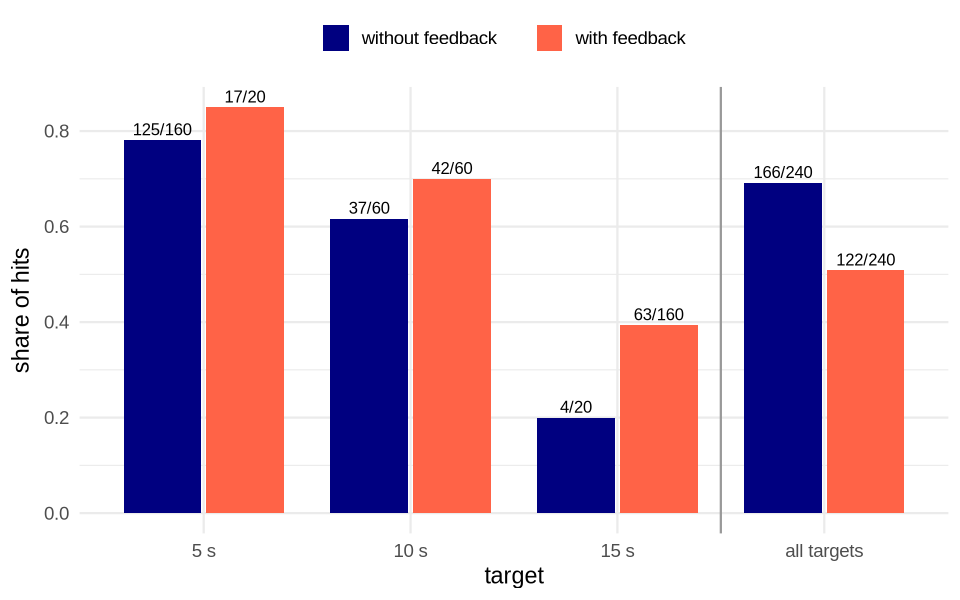

In [2]:
by_target <- pilot |> group_by(group = paste(target_seconds, "s"), condition) |>
  summarise(hits = sum(hit), attempts = n(), .groups = "drop")
overall <- pilot |> group_by(group = "all targets", condition) |>
  summarise(hits = sum(hit), attempts = n(), .groups = "drop")
table_pilot <- bind_rows(by_target, overall) |>
  mutate(share = hits / attempts,
         group = factor(group, levels = c("5 s", "10 s", "15 s", "all targets")))
table_pilot |> arrange(group)

ggplot(table_pilot, aes(x = group, y = share, fill = condition)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  geom_text(aes(label = paste0(hits, "/", attempts)), position = position_dodge(width = 0.8), vjust = -0.4, size = 3.5) +
  geom_vline(xintercept = 3.5, colour = "grey60") +
  scale_fill_manual(values = condition_colours, name = NULL) +
  labs(x = "target", y = "share of hits")

## 2. Why it happens

*Slide "Why it happens".* The two conditions have very different mixes of targets, and hits get rarer as the target grows. Each overall share is a weighted average of the three target shares.

In [3]:
mix <- pilot |> count(condition, target_seconds) |>
  group_by(condition) |> mutate(weight = n / sum(n)) |> ungroup()
mix

# overall share = sum of weight x share at that target
by_target |>
  mutate(target_seconds = as.numeric(str_remove(group, " s")), share = hits / attempts) |>
  left_join(mix, by = c("condition", "target_seconds")) |>
  group_by(condition) |>
  summarise(overall_share = sum(weight * share))

condition,target_seconds,n,weight
<fct>,<dbl>,<int>,<dbl>
without feedback,5,160,0.66666667
without feedback,10,60,0.25000000
without feedback,15,20,0.08333333
with feedback,5,20,0.08333333
with feedback,10,60,0.25000000
with feedback,15,160,0.66666667


condition,overall_share
<fct>,<dbl>
without feedback,0.6916667
with feedback,0.5083333


## 3. It happens in real data: kidney stones

*Slide "It happens in real data: kidney stones".* Successful treatments from Charig et al. (1986, BMJ 292: 879–882): treatment A is open surgery, B a less invasive procedure.

In [4]:
stones <- bind_rows(
  tibble(treatment = "A", stones = "small", success = 81,  patients = 87),
  tibble(treatment = "A", stones = "large", success = 192, patients = 263),
  tibble(treatment = "B", stones = "small", success = 234, patients = 270),
  tibble(treatment = "B", stones = "large", success = 55,  patients = 80))
stones |> mutate(share = success / patients)
stones |> group_by(treatment) |> summarise(success = sum(success), patients = sum(patients), share = success / patients)

treatment,stones,success,patients,share
<chr>,<chr>,<dbl>,<dbl>,<dbl>
A,small,81,87,0.9310345
A,large,192,263,0.7300380
B,small,234,270,0.8666667
B,large,55,80,0.6875000


treatment,success,patients,share
<chr>,<dbl>,<dbl>,<dbl>
A,273,350,0.7800000
B,289,350,0.8257143


## 4. Two logistic models, two answers

*Slide "Two logistic models, two answers".* The same Stan program as this morning, with two design matrices:

- Model 1: X has one column, feedback;
- Model 2: X has two columns, the centred target and feedback.

The six rows of `X_new` in Model 2 are every target with and without feedback, used in section 5.

Running MCMC with 4 sequential chains...

Chain 1 finished in 0.3 seconds.
Chain 2 finished in 0.3 seconds.
Chain 3 finished in 0.3 seconds.
Chain 4 finished in 0.4 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.3 seconds.
Total execution time: 1.8 seconds.



Running MCMC with 4 sequential chains...

Chain 1 finished in 0.4 seconds.
Chain 2 finished in 0.5 seconds.
Chain 3 finished in 0.4 seconds.
Chain 4 finished in 0.4 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.4 seconds.
Total execution time: 2.1 seconds.



variable,mean,5%,95%,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
alpha,0.7926412,0.5736998,1.0201450,1.004076,1378.789
beta[1],-0.7480919,-1.0507870,-0.4494331,1.002356,1377.738


variable,mean,5%,95%,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
alpha,0.2309623,-0.03208020,0.5041753,1.003334,1270.127
beta[1],-0.2266006,-0.28088347,-0.1744087,1.000955,1471.185
beta[2],0.4915662,0.05446368,0.9280316,1.002024,1181.673


model,beta_f_q5,beta_f_q95,odds_ratio_q5,odds_ratio_q95,P_feedback_helps
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1: feedback only,-1.05078704,-0.4494331,0.3496624,0.6379897,0.000
2: feedback and target,0.05446368,0.9280316,1.0559741,2.5295253,0.969


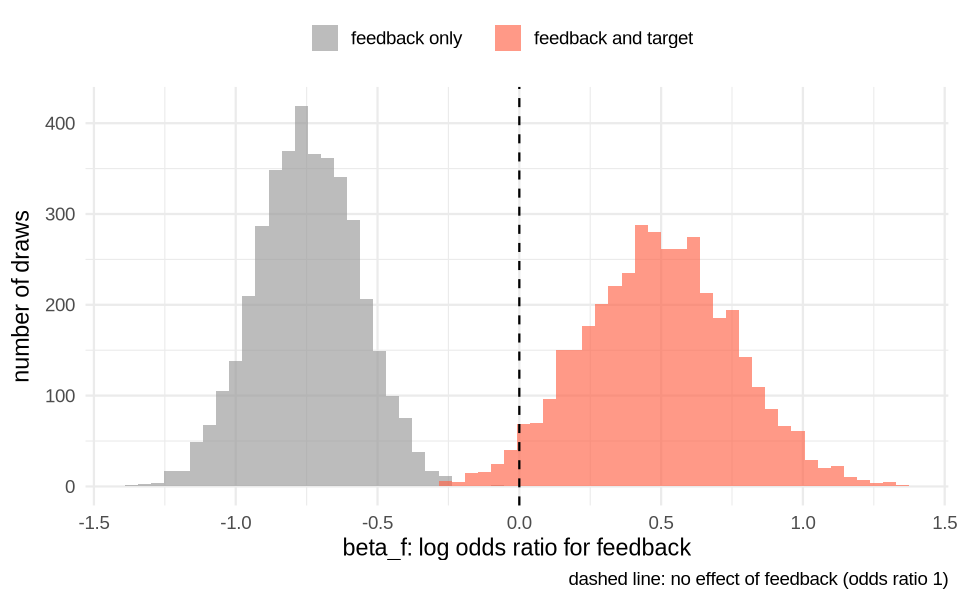

In [5]:
mod <- cmdstan_model("models/logistic.stan")

X1 <- cbind(feedback = pilot$feedback)
data1 <- list(N = nrow(pilot), K = 1, X = X1, y = pilot$hit, prior_sd = 1, M = 2, X_new = cbind(feedback = c(0, 1)))

cases <- expand_grid(feedback = c(0, 1), target_seconds = c(5, 10, 15))
X2 <- cbind(x = pilot$x, feedback = pilot$feedback)
data2 <- list(N = nrow(pilot), K = 2, X = X2, y = pilot$hit, prior_sd = c(0.5, 1),
              M = nrow(cases), X_new = cbind(x = cases$target_seconds - 10, feedback = cases$feedback))

fit1 <- mod$sample(data = data1, chains = 4, seed = 2026, refresh = 0)
fit2 <- mod$sample(data = data2, chains = 4, seed = 2026, refresh = 0)
fit1$summary(c("alpha", "beta"), "mean", ~quantile(.x, c(0.05, 0.95)), "rhat", "ess_bulk")
fit2$summary(c("alpha", "beta"), "mean", ~quantile(.x, c(0.05, 0.95)), "rhat", "ess_bulk")

draws1 <- fit1$draws(format = "df") |> as_tibble()
draws2 <- fit2$draws(format = "df") |> as_tibble()
tibble(model = c("1: feedback only", "2: feedback and target"),
       beta_f_q5  = c(quantile(draws1$`beta[1]`, 0.05), quantile(draws2$`beta[2]`, 0.05)),
       beta_f_q95 = c(quantile(draws1$`beta[1]`, 0.95), quantile(draws2$`beta[2]`, 0.95)),
       odds_ratio_q5  = exp(beta_f_q5), odds_ratio_q95 = exp(beta_f_q95),
       P_feedback_helps = c(mean(draws1$`beta[1]` > 0), mean(draws2$`beta[2]` > 0)))

beta_f <- bind_rows(tibble(model = "feedback only",       b = draws1$`beta[1]`),
                    tibble(model = "feedback and target", b = draws2$`beta[2]`)) |>
  mutate(model = factor(model, levels = c("feedback only", "feedback and target")))
ggplot(beta_f, aes(x = b, fill = model)) +
  geom_histogram(bins = 60, alpha = 0.65, position = "identity") +
  geom_vline(xintercept = 0, linetype = "dashed") +
  scale_fill_manual(values = c("feedback only" = "grey60", "feedback and target" = "tomato"), name = NULL) +
  labs(x = "beta_f: log odds ratio for feedback", y = "number of draws", caption = "dashed line: no effect of feedback (odds ratio 1)")

## 5. A fair overall comparison

*Slide "A fair overall comparison".* From Model 2, average the predicted P(hit) over the same mix of targets for both conditions: here an equal mix of 5, 10 and 15 s. Rows 1–3 of `X_new` are without feedback, rows 4–6 with feedback.

In [6]:
p_without <- (draws2$`p_new[1]` + draws2$`p_new[2]` + draws2$`p_new[3]`) / 3
p_with    <- (draws2$`p_new[4]` + draws2$`p_new[5]` + draws2$`p_new[6]`) / 3
tibble(quantity = c("without feedback", "with feedback", "difference"),
       mean = c(mean(p_without), mean(p_with), mean(p_with - p_without)),
       q5   = c(quantile(p_without, 0.05), quantile(p_with, 0.05), quantile(p_with - p_without, 0.05)),
       q95  = c(quantile(p_without, 0.95), quantile(p_with, 0.95), quantile(p_with - p_without, 0.95)))
c(P_difference_positive = mean(p_with > p_without))

quantity,mean,q5,q95
<chr>,<dbl>,<dbl>,<dbl>
without feedback,0.54799589,0.49385468,0.6067021
with feedback,0.64411606,0.59490808,0.6914433
difference,0.09612016,0.01141165,0.1746717


P_difference_positive 
                0.969

## 6. Worked example, question 1: the same mix, from the table

*Slide "Worked example: answers".* Reweight the shares with feedback by the target mix of the attempts **without** feedback (160, 60 and 20 attempts).

In [7]:
shares <- by_target |> mutate(target_seconds = as.numeric(str_remove(group, " s")), share = hits / attempts)
weights_without <- mix |> filter(condition == "without feedback") |> select(target_seconds, weight)
shares |> left_join(weights_without, by = "target_seconds") |>
  group_by(condition) |>
  summarise(share_with_the_same_mix = sum(weight * share))

condition,share_with_the_same_mix
<fct>,<dbl>
without feedback,0.6916667
with feedback,0.7744792


## 7. Worked example, question 3: a feedback effect that depends on the target

*Slide "Worked example: answers".* Add a third column x × f to the design matrix. Its coefficient is how much the feedback shift on the log-odds changes per second of target. The Stan program does not change.

In [8]:
X3 <- cbind(x = pilot$x, feedback = pilot$feedback, x_times_feedback = pilot$x * pilot$feedback)
data3 <- list(N = nrow(pilot), K = 3, X = X3, y = pilot$hit, prior_sd = c(0.5, 1, 0.5),
              M = 0, X_new = matrix(0, nrow = 0, ncol = 3))
fit3 <- mod$sample(data = data3, chains = 4, seed = 2026, refresh = 0)
fit3$summary(c("alpha", "beta"), "mean", ~quantile(.x, c(0.05, 0.95)), "rhat", "ess_bulk")

Running MCMC with 4 sequential chains...

Chain 1 finished in 0.6 seconds.
Chain 2 finished in 0.6 seconds.
Chain 3 finished in 0.6 seconds.
Chain 4 finished in 0.5 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.6 seconds.
Total execution time: 2.6 seconds.



variable,mean,5%,95%,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
alpha,0.24675869,-0.05033587,0.54475893,1.001512,1490.530
beta[1],-0.22147516,-0.29414458,-0.14976202,1.000987,1761.637
beta[2],0.51073792,0.07374047,0.97527466,1.001694,1701.389
beta[3],-0.01498786,-0.12309652,0.08902783,1.001500,2026.484
